# RAVDESS: exploratory data analysis

Can RAVDESS join CREMA-D in this project, as a third federated client and as a cross-corpus test set? This
notebook looks at what RAVDESS contains, how it was recorded, and which of our five task heads its labels can
feed, always side by side with CREMA-D (`notebooks/eda.ipynb`, same section style).

Source: Livingstone & Russo (2018), *The Ryerson Audio-Visual Database of Emotional Speech and Song (RAVDESS)*,
PLoS ONE 13(5): e0196391. Data: Zenodo record 1188976 (DOI 10.5281/zenodo.1188976), licence **CC BY-NC-SA 4.0**
(non-commercial: fine for the paper, not for a product). Stored outside the repo in `../data/RAVDESS/`.

**Contents**
1. What was downloaded, and is it complete
2. What a clip is: the file-name code
3. How the recordings were organised (the grid)
4. Calm and surprised: does calm belong with neutral? (decision: drop both)
5. How far apart are the corpora? Non-IID evidence for federated learning
6. Audio length, silence and the 4-second window
7. Discussion: what this means for training, and how to treat the data
8. Video: what the model sees from each corpus (kiosk view)
9. Zero-shot: do our trained CREMA-D models work on RAVDESS?
10. Where does the visual encoder look? (Grad-CAM)


In [1]:
import re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from mffer.config import load_paths
from mffer.data.cremad import VALENCE as CREMAD_VALENCE

paths = load_paths()
clips_cd = pd.read_csv(paths.processed / "clips.csv")            # CREMA-D, for comparison
RAV = paths.raw.parent / "RAVDESS"

# Same chart style as notebooks/eda.ipynb.
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (8, 3.2), "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#bdbcb6", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#ecebe7", "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "normal", "axes.titlelocation": "left",
})

## 1. What was downloaded, and is it complete

Zenodo splits RAVDESS into 49 zip files (25.6 GB): audio-only speech and song (one zip each) and one
audio-visual zip per actor for speech and for song. Each zip was checked against Zenodo's MD5 before use.
The paper reports **1,440 speech files per modality**: 24 actors × 60 recordings.

In [2]:
files = sorted(RAV.glob("audio_speech/Actor_*/*.wav"))
print(f"audio speech files: {len(files)}  (paper: 1440)")
print(f"actor folders: {len({f.parent.name for f in files})}  (paper: 24)")
print("examples:", *[f.name for f in files[:3]])

audio speech files: 1440  (paper: 1440)
actor folders: 24  (paper: 24)
examples: 03-01-01-01-01-01-01.wav 03-01-01-01-01-02-01.wav 03-01-01-01-02-01-01.wav


## 2. What a clip is: the file-name code

Unlike CREMA-D (`1001_ITS_HAP_XX`), a RAVDESS file name is **seven two-digit fields**, and every label is in it:

| Field | Values |
|---|---|
| modality | 01 audio-video, 02 video only, 03 audio only |
| vocal channel | 01 speech, 02 song |
| emotion | 01 neutral, 02 calm, 03 happy, 04 sad, 05 angry, 06 fearful, 07 disgust, 08 surprised |
| intensity | 01 normal, 02 strong (neutral has no strong) |
| statement | 01 "Kids are talking by the door", 02 "Dogs are sitting by the door" |
| repetition | 01 first, 02 second take |
| actor | 01–24; odd = male, even = female |

So `03-01-06-01-02-01-12.wav` = audio only, speech, fearful, normal intensity, "Dogs…", first take, actor 12
(female). The clip table below is built from the names alone.

In [3]:
FIELDS = ["modality", "channel", "emotion", "intensity", "statement", "repetition", "actor"]
EMOTION = {1: "neutral", 2: "calm", 3: "happy", 4: "sad", 5: "angry", 6: "fearful", 7: "disgust", 8: "surprised"}
NAME = re.compile(r"^(\d\d)-(\d\d)-(\d\d)-(\d\d)-(\d\d)-(\d\d)-(\d\d)\.wav$")

rows = []
for f in files:
    m = NAME.match(f.name)
    assert m, f"unexpected file name {f.name}"
    rows.append(dict(zip(FIELDS, map(int, m.groups())), file=f.name))
rav = pd.DataFrame(rows)
assert (rav.modality == 3).all() and (rav.channel == 1).all()          # audio-only speech, as downloaded
assert (rav.actor.astype(str).str.zfill(2) == [f.parent.name[-2:] for f in files]).all()  # name matches folder
rav["emotion"] = rav.emotion.map(EMOTION)
rav["intensity"] = rav.intensity.map({1: "normal", 2: "strong"})
rav["sex"] = np.where(rav.actor % 2 == 1, "Male", "Female")
rav.head()

,modality,channel,emotion,intensity,statement,repetition,actor,file,sex
0,3,1,neutral,normal,1,1,1,03-01-01-01-01-01-01.wav,Male
1,3,1,neutral,normal,1,2,1,03-01-01-01-01-02-01.wav,Male
2,3,1,neutral,normal,2,1,1,03-01-01-01-02-01-01.wav,Male
3,3,1,neutral,normal,2,2,1,03-01-01-01-02-02-01.wav,Male
4,3,1,calm,normal,1,1,1,03-01-02-01-01-01-01.wav,Male


## 3. How the recordings were organised (the grid)

Like CREMA-D, RAVDESS is a **full grid**, but a much denser one per actor and far fewer actors:

- every actor says **2 statements × 2 takes** in each emotion;
- the 7 non-neutral emotions come at **two intensities** (normal, strong); neutral only at normal;
- so 7 × 2 × 2 × 2 + 1 × 2 × 2 = **60 clips per actor**, 24 actors, 1,440 clips.

CREMA-D has 91 actors × ~82 clips over 12 sentences and controls intensity for one sentence only (IEO).

In [4]:
per_actor = rav.groupby("actor").size()
print(f"clips per actor: min {per_actor.min()}, max {per_actor.max()}; actors: {rav.actor.nunique()} "
      f"({(rav.groupby('actor').sex.first() == 'Male').sum()} male, {(rav.groupby('actor').sex.first() == 'Female').sum()} female)")
grid = rav.pivot_table(index="emotion", columns="intensity", values="file", aggfunc="count", fill_value=0)
grid = grid.loc[list(EMOTION.values())]
grid["total"] = grid.sum(axis=1)
grid

clips per actor: min 60, max 60; actors: 24 (12 male, 12 female)


intensity,normal,strong,total
emotion,,,
neutral,96,0,96
calm,96,96,192
happy,96,96,192
sad,96,96,192
angry,96,96,192
fearful,96,96,192
disgust,96,96,192
surprised,96,96,192


In [5]:
compare = pd.DataFrame({
    "CREMA-D": [clips_cd.actor_id.nunique(), len(clips_cd), clips_cd.sentence.nunique(),
                clips_cd.displayed_emotion.nunique(), "IEO only (LO/MD/HI)", round(len(clips_cd) / clips_cd.actor_id.nunique(), 1)],
    "RAVDESS speech": [rav.actor.nunique(), len(rav), rav.statement.nunique(), rav.emotion.nunique(),
                       "every clip (normal/strong)", round(len(rav) / rav.actor.nunique(), 1)],
}, index=["actors", "clips", "sentences", "emotions", "intensity instruction", "clips per actor"])
compare

,CREMA-D,RAVDESS speech
actors,91,24
clips,7442,1440
sentences,12,2
emotions,6,8
intensity instruction,IEO only (LO/MD/HI),every clip (normal/strong)
clips per actor,81.8,60.0


**Takeaways**
- RAVDESS is complete (1,440 speech clips, 24 actors, 60 each, 12 male / 12 female) and a perfect grid: no
  missing recordings, unlike CREMA-D's 76–81-clip actors.
- It is wide where CREMA-D is narrow: **every** clip carries an intensity instruction (normal/strong), while
  CREMA-D controls intensity on one sentence only. And narrow where CREMA-D is wide: 24 actors instead of 91, 2
  sentences instead of 12. With 60 clips of the same two lines per actor, a model can learn the speaker.
- Every line is recorded **twice** (two takes): near-duplicates. Splits must keep each actor in one part.
- Neutral is half-sized by design (no strong version): 96 clips against 192 for every other emotion.

## 4. Calm and surprised: does calm belong with neutral?

RAVDESS has two emotions CREMA-D lacks. Our heads predict CREMA-D's six and derive valence from them, so each
extra emotion must be mapped or dropped. **Surprised** (valence ambiguous: pleasant or not) is dropped in every
option considered. **Calm** is the open question: merging it into neutral (1,248 clips, neutral 23%) is common
in the speech-emotion literature, but calm was acted as a distinct, low-arousal, mildly positive state.

This section puts calm next to neutral and three anchors (happy, sad, and the other emotions) three ways:
**listen**, **look** (spectrograms, acoustic descriptors, a 2-D map), and **test** (can a simple classifier tell
them apart on actors it never saw?). Faces follow in the video section.

Every descriptor is **normalised within actor** (z-score over that actor's 60 clips): voices differ far more
between people than between one person's emotions, and with only 24 actors, raw values mostly measure who is
speaking.

In [6]:
import librosa, librosa.display
from IPython.display import Audio, HTML, display

SR = 16000                                               # CREMA-D's rate; RAVDESS files are 48 kHz
CACHE = RAV / "audio_descriptors.csv"

def describe(path):
    y, _ = librosa.load(path, sr=SR)
    if len(y) < SR // 4:                                 # broken recording (< 0.25 s): described as missing
        return {}
    speech, (start, end) = librosa.effects.trim(y, top_db=30)   # cut the leading/trailing silence
    rms = librosa.feature.rms(y=speech, frame_length=400, hop_length=160)[0]
    f0 = librosa.yin(speech, fmin=65, fmax=500, sr=SR, frame_length=1024, hop_length=160)
    n = min(len(f0), len(rms)); voiced = rms[:n] > np.percentile(rms[:n], 40)   # pitch on the louder frames only
    semitones = 12 * np.log2(f0[:n][voiced] / 100)
    if len(semitones) == 0:                              # (near-)silent file: no pitch to measure
        semitones = np.array([np.nan, np.nan])
    mfcc = librosa.feature.mfcc(y=speech, sr=SR, n_mfcc=13, n_fft=400, hop_length=160)
    return dict(duration_s=len(y) / SR, speech_s=len(speech) / SR, lead_s=start / SR, trail_s=(len(y) - end) / SR,
                loudness_db=20 * np.log10(rms.mean() + 1e-9),
                loudness_spread_db=20 * np.log10(np.percentile(rms, 95) + 1e-9) - 20 * np.log10(np.percentile(rms, 20) + 1e-9),
                pitch_st=np.median(semitones), pitch_range_st=np.subtract(*np.percentile(semitones, [90, 10])),
                **{f"mfcc{i}_mean": v for i, v in enumerate(mfcc.mean(1))},
                **{f"mfcc{i}_std": v for i, v in enumerate(mfcc.std(1))})

if CACHE.exists():
    desc = pd.read_csv(CACHE)
else:
    from joblib import Parallel, delayed
    desc = pd.DataFrame(Parallel(n_jobs=8)(delayed(describe)(RAV / "audio_speech" / f"Actor_{a:02d}" / f)
                                           for a, f in zip(rav.actor, rav.file)))
    desc.insert(0, "file", rav.file.values)
    desc.to_csv(CACHE, index=False)
assert (desc.file == rav.file).all()
FEATURES = [c for c in desc.columns if c != "file"]
z = desc[FEATURES].groupby(rav.actor).transform(lambda s: (s - s.mean()) / s.std())   # within-actor z-scores
rav["group"] = np.where(rav.emotion == "calm", "calm " + rav.intensity, rav.emotion)
print(f"{len(desc)} clips described; speech length {desc.speech_s.median():.2f} s median "
      f"(file {desc.duration_s.median():.2f} s)")

1440 clips described; speech length 1.79 s median (file 3.67 s)


### 4a. Listen

The same actor and line (*"Kids are talking by the door"*, first take) in five states. One male (actor 1) and
one female (actor 2) voice.

In [7]:
ORDER = ["neutral", "calm normal", "calm strong", "happy", "sad"]

def clip(actor, group, statement=1, take=1):
    emotion, _, intensity = group.partition(" ")
    hit = rav[(rav.actor == actor) & (rav.emotion == emotion) & (rav.statement == statement) & (rav.repetition == take)
              & (rav.intensity == (intensity or "normal"))]
    return RAV / "audio_speech" / f"Actor_{actor:02d}" / hit.file.iloc[0]

for actor in (1, 2):
    cells = []
    for group in ORDER:
        y, _ = librosa.load(clip(actor, group), sr=SR)
        cells.append(f"<td style='text-align:center'>{group}<br>{Audio(y, rate=SR)._repr_html_()}</td>")
    display(HTML(f"<b>Actor {actor} ({'male' if actor % 2 else 'female'})</b><table><tr>{''.join(cells)}</tr></table>"))

/root/miniforge3/envs/mffer/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


neutral Your browser does not support the audio element.,calm normal Your browser does not support the audio element.,calm strong Your browser does not support the audio element.,happy Your browser does not support the audio element.,sad Your browser does not support the audio element.


neutral Your browser does not support the audio element.,calm normal Your browser does not support the audio element.,calm strong Your browser does not support the audio element.,happy Your browser does not support the audio element.,sad Your browser does not support the audio element.


### 4b. Look: spectrograms

Log-mel spectrograms (64 bands, 10 ms hop: the log-mel input of ADR 0020), same clips as above. Brighter =
louder. Calm-as-neutral would show the same flat energy and pitch contour as neutral; calm-as-its-own-state
would look softer and slower than neutral, or show happy's movement at lower energy.

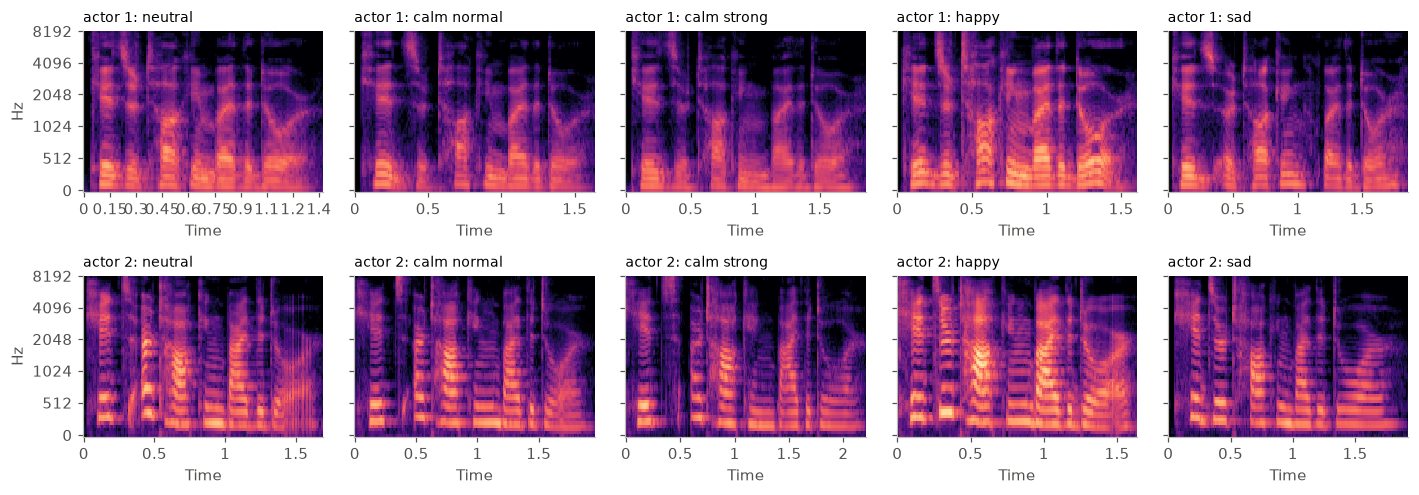

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(13, 4.6), sharey=True)
for r, actor in enumerate((1, 2)):
    for c, group in enumerate(ORDER):
        y, _ = librosa.load(clip(actor, group), sr=SR)
        y, _ = librosa.effects.trim(y, top_db=30)
        mel = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=SR, n_fft=400, hop_length=160, n_mels=64), ref=1.0)
        librosa.display.specshow(mel, sr=SR, hop_length=160, x_axis="time", y_axis="mel", ax=axes[r, c],
                                 vmin=-80, vmax=0, cmap="magma")
        axes[r, c].set_title(f"actor {actor}: {group}", fontsize=9); axes[r, c].grid(False)
        if c: axes[r, c].set_ylabel("")
plt.tight_layout(); plt.show()

### 4c. Look: acoustic descriptors over all 24 actors

Each box is 96 clips (neutral, calm normal, calm strong) or 192 (happy, sad), within-actor z-scores: 0 = that
actor's average delivery. Loudness and pitch are the classic arousal cues; speech length is a tempo cue (same
words, so longer = slower).

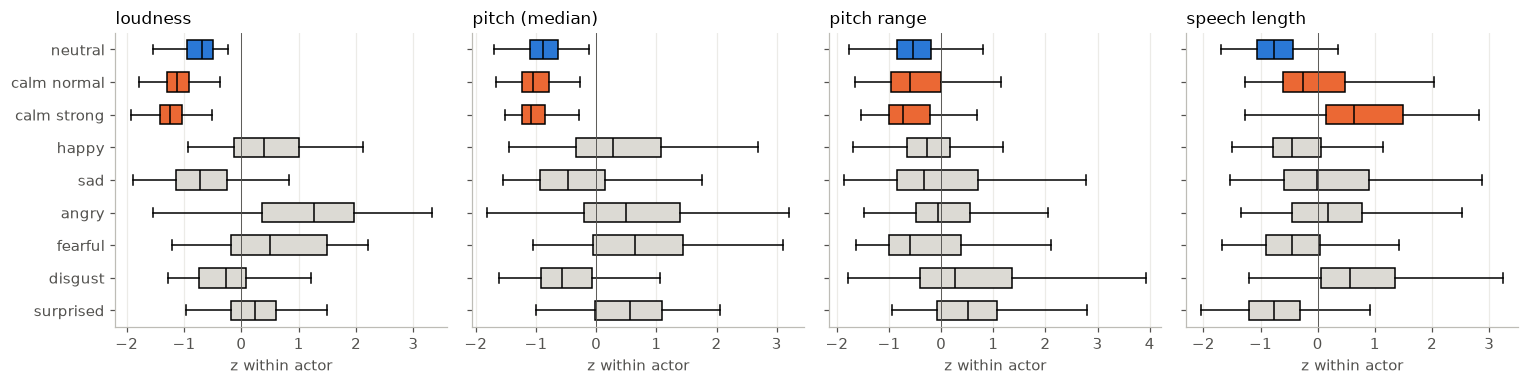

,loudness_db,pitch_st,pitch_range_st,speech_s
group,,,,
neutral,-0.69,-0.89,-0.55,-0.76
calm normal,-1.12,-1.04,-0.60,-0.27
calm strong,-1.24,-1.08,-0.74,0.63
happy,0.40,0.28,-0.27,-0.46
sad,-0.71,-0.46,-0.33,-0.01
angry,1.27,0.49,-0.06,0.18
fearful,0.49,0.64,-0.59,-0.45
disgust,-0.27,-0.56,0.26,0.57
surprised,0.24,0.57,0.51,-0.76


In [9]:
SHOW = {"loudness_db": "loudness", "pitch_st": "pitch (median)", "pitch_range_st": "pitch range", "speech_s": "speech length"}
groups = ["neutral", "calm normal", "calm strong", "happy", "sad", "angry", "fearful", "disgust", "surprised"]
colors = {"neutral": BLUE, "calm normal": ORANGE, "calm strong": ORANGE}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
for ax, (feature, label) in zip(axes, SHOW.items()):
    data = [z.loc[rav.group == g, feature] for g in groups]
    box = ax.boxplot(data, orientation="horizontal", widths=0.6, showfliers=False, patch_artist=True, medianprops={"color": "black"})
    for patch, g in zip(box["boxes"], groups):
        patch.set_facecolor(colors.get(g, "#dcdad4"))
    ax.set_yticks(range(1, len(groups) + 1), groups); ax.axvline(0, color=MUTED, lw=0.6)
    ax.set_title(label); ax.set_xlabel("z within actor"); ax.grid(axis="x", color="#ecebe7"); ax.grid(axis="y", visible=False)
ax.invert_yaxis(); plt.tight_layout(); plt.show()
z.assign(group=rav.group).groupby("group")[list(SHOW)].median().loc[groups].round(2)

### 4d. Look: one map of all clips

Every clip's 26 MFCC statistics (mean and spread of 13 coefficients, within-actor z-scores) projected to 2-D
with PCA. Calm and neutral are highlighted; everything else is grey. If calm is "neutral", the two clouds
overlap; if it is its own state, calm sits apart or drifts toward another emotion.

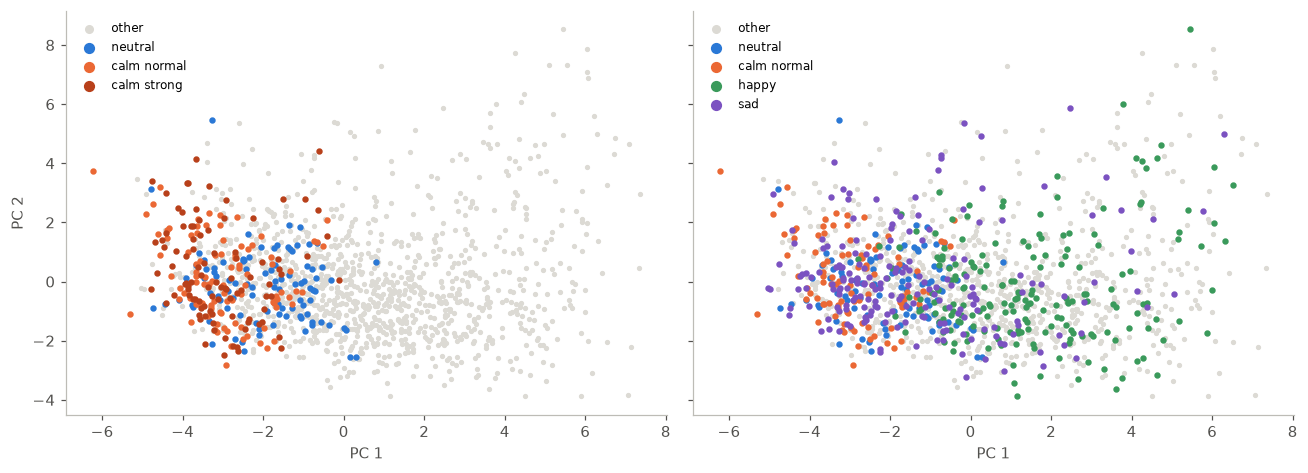

In [10]:
from sklearn.decomposition import PCA

MFCC = [c for c in FEATURES if c.startswith("mfcc")]
xy = PCA(2, random_state=0).fit_transform(z[MFCC].fillna(0))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharex=True, sharey=True)
for ax, highlight in zip(axes, [("neutral", "calm normal", "calm strong"), ("neutral", "calm normal", "happy", "sad")]):
    ax.scatter(*xy.T, s=6, color="#dcdad4", label="other")
    palette = {"neutral": BLUE, "calm normal": ORANGE, "calm strong": "#b8401a", "happy": "#3a9a5b", "sad": "#7b52c1"}
    for g in highlight:
        m = (rav.group == g).values
        ax.scatter(*xy[m].T, s=10, color=palette[g], label=g)
    ax.legend(markerscale=2, frameon=False, fontsize=8); ax.set_xlabel("PC 1"); ax.grid(False)
axes[0].set_ylabel("PC 2"); plt.tight_layout(); plt.show()

### 4e. Test: can a classifier tell them apart on unseen actors?

A logistic regression on the 26 MFCC statistics plus loudness, pitch and speech length (all within-actor
z-scores), scored with **6-fold cross-validation by actor** (4 test actors per fold, never seen in training).
Each pair is balanced (strong-intensity clips excluded, since neutral has none), so **50% = indistinguishable**.
Reference pairs show what "clearly different" and "similar" look like.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_all = z[MFCC + list(SHOW)].fillna(0)
def separability(a, b):
    m = rav.emotion.isin([a, b]) & (rav.intensity == "normal")
    X, y, g = X_all[m], (rav.emotion[m] == a).astype(int), rav.actor[m]
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.5))
    scores = cross_val_score(model, X, y, groups=g, cv=GroupKFold(6), scoring="balanced_accuracy")
    return scores.mean(), scores.std()

pairs = [("calm", "neutral"), ("calm", "sad"), ("calm", "happy"), ("neutral", "sad"), ("neutral", "happy"),
         ("happy", "angry"), ("sad", "fearful")]
sep = pd.DataFrame([(f"{a} vs {b}", *separability(a, b)) for a, b in pairs],
                   columns=["pair", "balanced accuracy", "sd over folds"]).set_index("pair")
sep.style.format("{:.1%}").bar(subset=["balanced accuracy"], vmin=0.5, vmax=1.0, color="#cfe0f6")

,balanced accuracy,sd over folds
pair,,
calm vs neutral,76.0%,8.4%
calm vs sad,55.2%,13.2%
calm vs happy,92.2%,5.3%
neutral vs sad,71.9%,7.0%
neutral vs happy,82.3%,2.9%
happy vs angry,90.6%,8.1%
sad vs fearful,94.3%,3.8%


**Takeaways (calm, audio only)**
- **Calm is not neutral, acoustically.** Calm is quieter than neutral (loudness z −1.1 vs −0.7), equally low in
  pitch, and clearly **slower** (speech length z −0.3, and +0.6 at strong intensity, vs −0.8 for neutral): calm
  sounds like neutral spoken softly and slowly. A classifier separates calm from neutral on unseen actors at
  **76%** balanced accuracy, about as well as neutral from sad (72%).
- **Calm sounds like sad.** Calm vs sad is the hardest pair: **55%**, close to chance. On the 2-D map calm,
  neutral and sad share the same low-arousal corner, while happy sits clearly apart (calm vs happy 92%).
- **Risk for our primary metric.** Merging calm into neutral would put 192 sad-sounding clips into the *neutral*
  valence class, blurring exactly the neutral/negative boundary that valence macro-F1 depends on. The audio
  alone argues for **dropping calm**; the face (video section) decides whether calm looks pleasant-neutral, which
  would make the merge defensible for the visual and fused models.

### 4f. Decision: drop calm and surprised

**Both are dropped** (decided 25 Nov 2026). Neither exists in CREMA-D, so neither can be scored by our heads
without a mapping, and the audio evidence above argues against the only common mapping (calm → neutral). From
here on, `rav6` holds the **1,056 clips of the six shared emotions**. The same mapping as CREMA-D gives valence:
anger, disgust, fear, sad → negative; neutral → neutral; happy → positive.

In [12]:
TO_CREMAD = {"angry": "ANG", "disgust": "DIS", "fearful": "FEA", "happy": "HAP", "neutral": "NEU", "sad": "SAD"}
keep = rav.emotion.isin(TO_CREMAD)
rav6, z6, desc6 = rav[keep].reset_index(drop=True), z[keep].reset_index(drop=True), desc[keep].reset_index(drop=True)
rav6["emotion6"] = rav6.emotion.map(TO_CREMAD)
rav6["valence"] = rav6.emotion6.map(CREMAD_VALENCE)
print(f"{len(rav6)} clips kept of {len(rav)} ({len(rav) - len(rav6)} calm/surprised dropped); "
      f"{len(rav6) // rav6.actor.nunique()} per actor")

1056 clips kept of 1440 (384 calm/surprised dropped); 44 per actor


## 5. How far apart are the corpora? Non-IID evidence for federated learning

If CREMA-D and RAVDESS become two federated clients (or two groups of clients), the data is **non-IID by
construction**. The federated-learning literature separates four kinds of non-IID data; each is measured
below, so the paper can state *how* non-IID the setting is instead of assuming it:

| Kind | Question | Measured in |
|---|---|---|
| Quantity skew | do clients hold very different amounts of data? | 5a |
| Label skew | do clients see a different mix of classes? | 5b |
| Intensity (label definition) | does the same intensity label mean the same thing? | 5c |
| Feature skew | does the same class *sound* different per client? | 5d |
| Concept shift | does a model of one corpus transfer to the other? | 5e |

CREMA-D gets the same descriptors as RAVDESS (same code, 16 kHz, within-actor z-scores over each actor's
clips).

In [13]:
CD_CACHE = paths.processed / "cremad_audio_descriptors.csv"
if CD_CACHE.exists():
    desc_cd = pd.read_csv(CD_CACHE)
else:
    from joblib import Parallel, delayed
    desc_cd = pd.DataFrame(Parallel(n_jobs=8)(delayed(describe)(paths.raw / "AudioWAV" / f"{c}.wav")
                                              for c in clips_cd.clip_id))
    desc_cd.insert(0, "clip_id", clips_cd.clip_id.values)
    desc_cd.to_csv(CD_CACHE, index=False)
assert (desc_cd.clip_id == clips_cd.clip_id).all()
z_cd = desc_cd[FEATURES].groupby(clips_cd.actor_id).transform(lambda s: (s - s.mean()) / s.std())
print(f"CREMA-D: {len(desc_cd)} clips described")

CREMA-D: 7442 clips described


### 5a. Quantity skew

In [14]:
quantity = pd.DataFrame({
    "CREMA-D": [clips_cd.actor_id.nunique(), len(clips_cd), round(len(clips_cd) / clips_cd.actor_id.nunique(), 1)],
    "RAVDESS (6 emotions)": [rav6.actor.nunique(), len(rav6), round(len(rav6) / rav6.actor.nunique(), 1)],
}, index=["actors", "clips", "clips per actor"])
quantity["ratio"] = (quantity.iloc[:, 0] / quantity.iloc[:, 1]).round(1)
quantity

,CREMA-D,RAVDESS (6 emotions),ratio
actors,91.0,24.0,3.8
clips,7442.0,1056.0,7.0
clips per actor,81.8,44.0,1.9


### 5b. Label skew

Share of each emotion and valence class per corpus, and the Jensen–Shannon divergence between the two
distributions (0 = identical, 1 = no overlap; base 2).

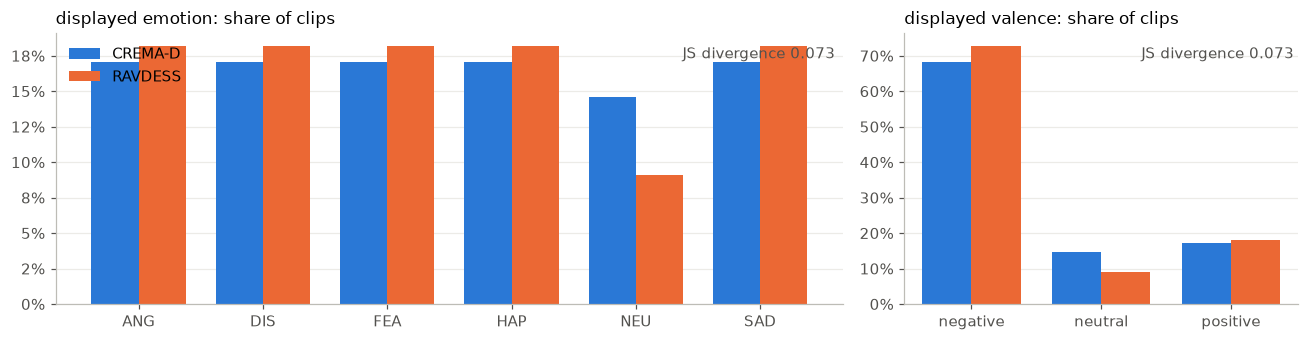

,CREMA-D,RAVDESS
ANG,17.1%,18.2%
DIS,17.1%,18.2%
FEA,17.1%,18.2%
HAP,17.1%,18.2%
NEU,14.6%,9.1%
SAD,17.1%,18.2%
negative,68.3%,72.7%
neutral,14.6%,9.1%
positive,17.1%,18.2%


In [15]:
from scipy.spatial.distance import jensenshannon

EMO = ["ANG", "DIS", "FEA", "HAP", "NEU", "SAD"]; VAL = ["negative", "neutral", "positive"]
emo = pd.DataFrame({"CREMA-D": clips_cd.displayed_emotion.value_counts(normalize=True),
                    "RAVDESS": rav6.emotion6.value_counts(normalize=True)}).loc[EMO]
val = pd.DataFrame({"CREMA-D": clips_cd.displayed_valence.value_counts(normalize=True),
                    "RAVDESS": rav6.valence.value_counts(normalize=True)}).loc[VAL]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), gridspec_kw={"width_ratios": [2, 1]})
for ax, table, title in [(axes[0], emo, "displayed emotion"), (axes[1], val, "displayed valence")]:
    x = np.arange(len(table)); w = 0.38
    ax.bar(x - w / 2, table["CREMA-D"], w, color=BLUE, label="CREMA-D")
    ax.bar(x + w / 2, table["RAVDESS"], w, color=ORANGE, label="RAVDESS")
    ax.set_xticks(x, table.index); ax.set_title(f"{title}: share of clips"); ax.yaxis.set_major_formatter("{x:.0%}")
    js = jensenshannon(table["CREMA-D"], table["RAVDESS"], base=2)
    ax.text(0.99, 0.95, f"JS divergence {js:.3f}", transform=ax.transAxes, ha="right", va="top", color=MUTED)
axes[0].legend(frameon=False); plt.tight_layout(); plt.show()
pd.concat([emo, val]).style.format("{:.1%}")

### 5c. Intensity: does "strong" mean "high"?

CREMA-D's displayed-intensity head is trained only on sentence IEO, at LO / MD / HI (targets 1/3, 2/3, 1).
RAVDESS asks for normal or strong on every non-neutral clip. Before mapping one onto the other, compare how
much each instruction actually changes the voice: loudness and pitch range, as within-actor z-scores (neutral
excluded on both sides).

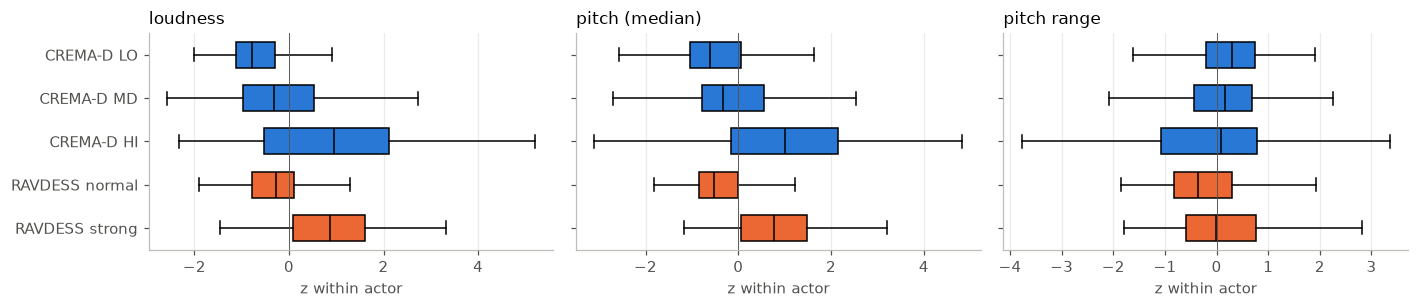

,loudness,pitch (median),pitch range
CREMA-D LO,-0.77,-0.61,0.31
CREMA-D MD,-0.32,-0.33,0.17
CREMA-D HI,0.96,1.00,0.08
RAVDESS normal,-0.28,-0.52,-0.37
RAVDESS strong,0.87,0.77,-0.02


In [16]:
cd_ieo = (clips_cd.sentence == "IEO") & (clips_cd.displayed_emotion != "NEU") & clips_cd.displayed_level.isin(["LO", "MD", "HI"])
rows_i = [("CREMA-D " + lvl, z_cd.loc[cd_ieo & (clips_cd.displayed_level == lvl)]) for lvl in ("LO", "MD", "HI")]
rows_i += [("RAVDESS " + lvl, z6.loc[(rav6.emotion6 != "NEU") & (rav6.intensity == lvl)]) for lvl in ("normal", "strong")]
INT_FEATS = {"loudness_db": "loudness", "pitch_st": "pitch (median)", "pitch_range_st": "pitch range"}

fig, axes = plt.subplots(1, 3, figsize=(13, 2.9), sharey=True)
for ax, (feature, label) in zip(axes, INT_FEATS.items()):
    box = ax.boxplot([r[feature].dropna() for _, r in rows_i], orientation="horizontal", widths=0.6, showfliers=False,
                     patch_artist=True, medianprops={"color": "black"})
    for patch, (name, _) in zip(box["boxes"], rows_i):
        patch.set_facecolor(BLUE if name.startswith("CREMA") else ORANGE)
    ax.set_yticks(range(1, len(rows_i) + 1), [n for n, _ in rows_i]); ax.axvline(0, color=MUTED, lw=0.6)
    ax.set_title(label); ax.set_xlabel("z within actor"); ax.grid(axis="x", color="#ecebe7"); ax.grid(axis="y", visible=False)
ax.invert_yaxis(); plt.tight_layout(); plt.show()

steps = pd.DataFrame({name: r[list(INT_FEATS)].median() for name, r in rows_i}).T.rename(columns=INT_FEATS)
steps.round(2)

### 5d. Feature skew: can a classifier tell which corpus a clip came from?

Two versions. **Raw** descriptors (as a microphone records them): this measures recording conditions (studio,
microphone, level, language accent). **Within-actor z-scores**: speaker and recording level removed, so what
remains is the *style* of acting. Each is scored with actor-grouped cross-validation (no actor in both train and
test); classes are balanced by subsampling CREMA-D to RAVDESS's size, so 50% = indistinguishable.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ALL = MFCC + list(SHOW)
rng = np.random.default_rng(0)
cd_sample = np.sort(rng.choice(len(clips_cd), len(rav6), replace=False))
def corpus_test(cd_table, rav_table):
    X = pd.concat([cd_table.iloc[cd_sample][ALL], rav_table[ALL]]).fillna(0)
    y = np.r_[np.zeros(len(cd_sample)), np.ones(len(rav6))]
    groups = np.r_[clips_cd.actor_id.values[cd_sample], 10_000 + rav6.actor.values]
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5))
    s = cross_val_score(model, X, y, groups=groups, cv=GroupKFold(6), scoring="balanced_accuracy")
    return f"{s.mean():.1%} ± {s.std():.1%}"

desc_cd6 = desc_cd.copy()
pd.DataFrame({"which corpus?": [corpus_test(desc_cd, desc6), corpus_test(z_cd, z6)]},
             index=["raw descriptors (recording + style)", "within-actor z-scores (style only)"])

,which corpus?
raw descriptors (recording + style),99.8% ± 0.2%
within-actor z-scores (style only),52.7% ± 2.6%


Where the corpora differ in raw terms, per descriptor:

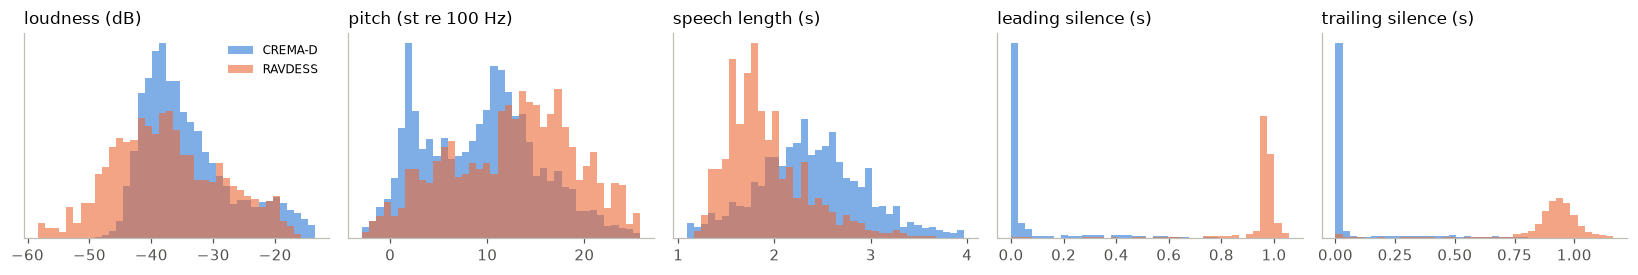

In [18]:
RAW = {"loudness_db": "loudness (dB)", "pitch_st": "pitch (st re 100 Hz)", "speech_s": "speech length (s)",
       "lead_s": "leading silence (s)", "trail_s": "trailing silence (s)"}
fig, axes = plt.subplots(1, 5, figsize=(15, 2.6))
for ax, (feature, label) in zip(axes, RAW.items()):
    a, b = desc_cd[feature].dropna(), desc6[feature].dropna()
    bins = np.linspace(min(a.quantile(0.01), b.quantile(0.01)), max(a.quantile(0.99), b.quantile(0.99)), 40)
    ax.hist(a, bins, density=True, color=BLUE, alpha=0.6, label="CREMA-D")
    ax.hist(b, bins, density=True, color=ORANGE, alpha=0.6, label="RAVDESS")
    ax.set_title(label); ax.set_yticks([])
axes[0].legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

### 5e. Concept shift: does a model of one corpus work on the other?

A 6-emotion classifier (same features, within-actor z-scores) trained on one corpus and tested on (a) unseen
actors of the same corpus and (b) all of the other corpus. The drop from (a) to (b) is the shift a single
shared model has to absorb. Chance is 1/6 = 16.7%. This is a weak linear model on hand-made features, so the
absolute numbers are low; the *gap* is what matters.

In [19]:
def emotion_model():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5))

corpora = {"CREMA-D": (z_cd[ALL].fillna(0), clips_cd.displayed_emotion.values, clips_cd.actor_id.values),
           "RAVDESS": (z6[ALL].fillna(0), rav6.emotion6.values, rav6.actor.values)}
transfer = {}
for train_name, (X, y, g) in corpora.items():
    within = cross_val_score(emotion_model(), X, y, groups=g, cv=GroupKFold(6), scoring="balanced_accuracy").mean()
    test_name = next(n for n in corpora if n != train_name)
    Xt, yt, _ = corpora[test_name]
    from sklearn.metrics import balanced_accuracy_score
    across = balanced_accuracy_score(yt, emotion_model().fit(X, y).predict(Xt))
    transfer[f"trained on {train_name}"] = {"same corpus, unseen actors": within, "other corpus": across,
                                            "drop (points)": 100 * (within - across)}
pd.DataFrame(transfer).T.style.format({"same corpus, unseen actors": "{:.1%}", "other corpus": "{:.1%}",
                                       "drop (points)": "{:+.1f}"})

,"same corpus, unseen actors",other corpus,drop (points)
trained on CREMA-D,61.0%,53.3%,+7.7
trained on RAVDESS,58.5%,42.8%,+15.7


**Takeaways (non-IID)**
- **Quantity skew: strong.** CREMA-D has 7× the clips and 3.8× the actors. Under FedAvg (weights ∝ clips) a
  CREMA-D client would contribute ~88% of every global update.
- **Label skew: mild.** The two corpora have almost the same emotion mix (JS divergence 0.07); the only real
  difference is neutral (9% in RAVDESS vs 15%), so RAVDESS is slightly *more* negative-heavy (73% vs 68%).
  Corpus-as-client therefore gives a **feature-skew** setting, not a label-skew one; a label-skewed setting would
  have to be made by partitioning emotions or actors on purpose.
- **Intensity: the mapping is clear.** RAVDESS *normal* moves the voice like CREMA-D *MD* (loudness z −0.28 vs
  −0.32), and *strong* like *HI* (+0.87 vs +0.96; pitch +0.77 vs +1.00). So **normal → 2/3, strong → 1** on our
  displayed-intensity scale. CREMA-D's LO has no RAVDESS counterpart.
- **Feature skew: very strong, but almost all of it is recording, not acting.** A linear classifier names the
  corpus of a clip **99.8%** of the time from raw descriptors, and **52.7%** (chance) once each actor's level and
  voice are normalised away. The raw histograms show where it comes from: RAVDESS is quieter and higher-pitched
  on average, its speech is shorter, and every RAVDESS file starts and ends with ~1 s of silence, which CREMA-D's
  files never do.
- **Concept shift: real.** Even on normalised features, a model trained on one corpus loses **8 points**
  (CREMA-D → RAVDESS) and **16 points** (RAVDESS → CREMA-D) on the other. The same emotion is acted differently
  enough that a shared model must absorb it; RAVDESS, with 24 actors, generalises worse.

## 6. Audio length, silence and the 4-second window

Our audio inputs cover a fixed **4 s** window from the start of the file (MFCC: 100 frames × 40 ms; log-mel:
400 × 10 ms), zero-padded or cut. CREMA-D's pipeline does **not** trim silence. What would the same pipeline do
to RAVDESS?

In [20]:
WINDOW = 4.0
def window_stats(d):
    speech_end = d.duration_s - d.trail_s
    return pd.Series({
        "file length (median s)": d.duration_s.median(),
        "speech (median s)": d.speech_s.median(),
        "leading silence (median s)": d.lead_s.median(),
        "trailing silence (median s)": d.trail_s.median(),
        "silence share of file": 1 - (d.speech_s / d.duration_s).median(),
        "files longer than 4 s": (d.duration_s > WINDOW).mean(),
        "speech cut by the window": (speech_end > WINDOW).mean(),
        # The model masks padding (zeros), not silence: silence frames are real, low-level frames.
        "silence among the real frames (untrimmed)": (1 - np.minimum(d.speech_s, np.clip(WINDOW - d.lead_s, 0, None))
                                                      / np.minimum(d.duration_s, WINDOW)).median(),
        "speech starts at (untrimmed, s)": d.lead_s.median(),
        "padding share of the window (trimmed)": (1 - np.minimum(d.speech_s, WINDOW) / WINDOW).median(),
    })
win = pd.DataFrame({"CREMA-D": window_stats(desc_cd), "RAVDESS": window_stats(desc6)})
SECONDS = [r for r in win.index if "(median s)" in r or r.endswith(", s)")]
win.style.format("{:.0%}").format("{:.2f}", subset=pd.IndexSlice[SECONDS, :])

,CREMA-D,RAVDESS
file length (median s),2.50,3.67
speech (median s),2.37,1.82
leading silence (median s),0.00,0.96
trailing silence (median s),0.00,0.93
silence share of file,0%,51%
files longer than 4 s,1%,19%
speech cut by the window,1%,1%
silence among the real frames (untrimmed),0%,51%
"speech starts at (untrimmed, s)",0.00,0.96
padding share of the window (trimmed),41%,54%


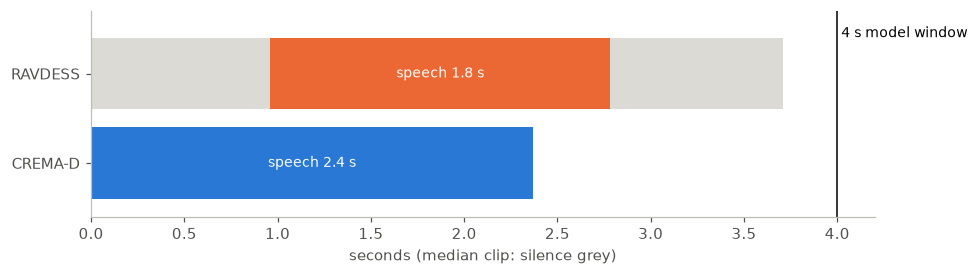

In [21]:
fig, ax = plt.subplots(figsize=(9, 2.6))
for i, (name, d, color) in enumerate([("CREMA-D", desc_cd, BLUE), ("RAVDESS", desc6, ORANGE)]):
    lead, speech, trail = d.lead_s.median(), d.speech_s.median(), d.trail_s.median()
    ax.barh(i, lead, color="#dcdad4"); ax.barh(i, speech, left=lead, color=color); ax.barh(i, trail, left=lead + speech, color="#dcdad4")
    ax.text(lead + speech / 2, i, f"speech {speech:.1f} s", ha="center", va="center", color="white", fontsize=9)
ax.axvline(WINDOW, color="black", lw=1); ax.text(WINDOW, 1.45, " 4 s model window", va="center", fontsize=9)
ax.set_yticks([0, 1], ["CREMA-D", "RAVDESS"]); ax.set_xlabel("seconds (median clip: silence grey)"); ax.grid(axis="y", visible=False)
ax.set_ylim(-0.6, 1.7); plt.tight_layout(); plt.show()

**Takeaways (length)**
- CREMA-D files are cut tightly around the speech (median 0.00 s silence either side); **RAVDESS files are about
  half silence**: ~1.0 s before and ~0.9 s after a 1.8 s utterance.
- The 4 s window is not the problem: after trimming, every RAVDESS utterance fits (median 1.8 s; only 1% of
  speech would be cut, and only without trimming).
- The problem is that **silence is not padding**. The pipeline zero-pads after the file ends, and masked pooling
  (ADR 0018) ignores those zeros, but RAVDESS's leading and trailing silence are real, low-level frames: the
  model would see ~1 s of room noise in front of every RAVDESS clip and never in front of a CREMA-D clip. That is
  a perfect corpus fingerprint, and exactly the kind of shortcut a model takes instead of learning emotion.

## 7. Discussion: what this means for training, and how to treat the data

Sections 1–6 turn into concrete choices. Each row says what the data showed, what it would do to training if
ignored, and the proposed treatment. These are proposals for the integration ADR, not yet decisions.

### 7a. Labels: which heads RAVDESS can feed

| Head | RAVDESS has | Treatment |
|---|---|---|
| displayed emotion | 6 shared emotions (calm, surprised dropped: §4) | same 6 classes |
| displayed valence | derived exactly as CREMA-D | same 3 classes |
| displayed intensity | normal / strong on every non-neutral clip | **normal → 2/3, strong → 1** (§5c); neutral masked, as in CREMA-D. Coverage jumps from 18% (CREMA-D) to 91% (RAVDESS) |
| perceived emotion / intensity | no per-clip crowd labels in the Zenodo release | **masked** (weight 0) for RAVDESS clips; the existing mask logic (ADR 0006) already handles a head without labels |

The coverage gap matters: the loss weight of a masked head is divided by its coverage on the training rows
(ADR 0006). In federated training each client sees a different coverage, so the compensation must be computed
**per client** (as class weights already are, ADR 0019), not once for the pooled data.

### 7b. Model inputs: which presets make sense

M3 (C2) uses two inputs RAVDESS cannot fill honestly: **text** is a one-hot of CREMA-D's 12 sentences (RAVDESS
has 2 different ones), and **demographics** needs each actor's age (RAVDESS gives sex only, from the actor
number). Filling them with zeros would make "text = zero" mean "RAVDESS", one more corpus fingerprint.
So cross-corpus experiments should use **D2** (deep visual encoder + gating, audio + video only). It is also our
best model so far, and D4 showed text adds nothing on CREMA-D.

### 7c. Audio: make the corpora differ only where they really differ

| Issue (section) | If ignored | Treatment |
|---|---|---|
| 48 kHz files | features at a different resolution | resample to 16 kHz (the pipeline already loads at 16 kHz) |
| ~1 s silence before and after every RAVDESS clip (§6) | perfect corpus fingerprint; RAVDESS's "speech" is half silence | **trim** leading/trailing silence (top_db 30) for **both** corpora, so one rule applies everywhere |
| level and recording differences (§5d: 99.8% → 52.7%) | the model can tell clients apart from the first frame; a global normaliser leaves the offset in | normalise with **each client's own** statistics (see 7d) |
| shorter speech (1.8 s vs 2.4 s) | more padding in RAVDESS windows | masked pooling (ADR 0018) makes padding irrelevant; worth switching on for multi-corpus runs |

### 7d. Federated learning: what the non-IID evidence implies

The current federated pipeline pools every client's audio statistics into **one global normaliser**
(`AudioStats.combine`, ADR 0008). That was right when every client was CREMA-D; across corpora it keeps the
recording offset of §5d in the inputs. Two options, both testable:

1. **Per-client normalisation**: each client standardises its audio with its own training statistics, and
   nothing about the statistics leaves the client (also a small privacy gain). §5d shows this alone should remove
   most of the corpus difference.
2. **FedBN** (Li et al., ICLR 2021): batch-norm layers stay local, everything else is averaged. Designed for
   exactly this case (feature-skewed clients) and a natural extra experiment next to FedAvg and FedProx (F4).

The quantity skew (7×) means **FedAvg's clip-weighted average lets CREMA-D dominate**. Results must therefore be
reported **per corpus**, never only pooled, or a model that ignores RAVDESS will still look good.

### 7e. Splits and evaluation

- **Actor-disjoint splits within RAVDESS**, like CREMA-D's: 24 actors → 16 train / 4 val / 4 test, each part
  sex-balanced (odd/even actor numbers), three frozen splits. Both takes of a line belong to one actor, so the
  near-duplicates never cross parts.
- The test part is small: 4 actors × 44 clips = 176 clips, about 16 neutral. Valence macro-F1 on that is noisy;
  three splits and per-split reporting are essential.
- **Evaluation grid** for the paper: each model on each corpus's test actors, plus cross-corpus transfer
  (trained on CREMA-D only, tested on RAVDESS, and back) as the "no collaboration" baseline next to local-only (L1).

### 7f. What is still open

- **Video** (next section, once the download finishes): RAVDESS is 1280×720, head-and-shoulders on a white
  background, vs CREMA-D's 480×360. The same fingerprint question applies to the face crop and background.
- Whether RAVDESS's perceptual validation ratings can be obtained per clip (they would un-mask the perceived
  heads).
- Licence: CC BY-NC-SA 4.0 is fine for the paper; any derived model weights inherit the non-commercial terms.

## 8. Video: what the model sees from each corpus

CAPE's Portuguese use case is a **smart kiosk**: a fixed, roughly frontal camera, one customer at a time, an
uncontrolled background, and data that stays on the device. So the video questions are: do the two corpora put
the face in the same place and at the same size, does the background give the corpus away, and do the ten
sampled frames actually show the person speaking?

Both corpora go through **our exact frame pipeline** (`mffer.data.features.frames`): ten frames spread evenly over
the whole file, a centred square crop, resized to 224×224. For CREMA-D the frames come straight from
`cremad.h5` (the raw `.flv` files are not stored locally); for RAVDESS they are extracted here from the
audio-video `.mp4` files (modality 01) with the same function.

Faces are found with **YuNet** (`cv2.FaceDetectorYN`, the small neural face detector of the OpenCV model zoo,
`face_detection_yunet_2023mar.onnx`, stored in `../data/models/`), run identically on both corpora.

In [22]:
import cv2, h5py
from joblib import Parallel, delayed
from mffer.data.features import frames as pipeline_frames

YUNET = paths.raw.parent / "models" / "face_detection_yunet_2023mar.onnx"
VIDEO_CACHE, MID_CACHE = RAV / "video_stats.csv", RAV / "video_mid_frames.npz"

def face_box(rgb, detector):
    _, found = detector.detect(cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))
    if found is None:
        return None
    x, y, w, h = max(found, key=lambda f: f[2] * f[3])[:4]       # largest face; (x, y, w, h)
    x, y = max(x, 0), max(y, 0)
    return np.array([x, y, min(w, 224 - x), min(h, 224 - y)])

def frame_stats(clip_frames):
    """Per clip, from the 10 pipeline frames: face box (median over frames), border/background colour,
    brightness, and motion (mean absolute change between consecutive frames, inside the face box)."""
    detector = cv2.FaceDetectorYN.create(str(YUNET), "", (224, 224), 0.6)
    boxes = [face_box(f, detector) for f in clip_frames]
    found = [b for b in boxes if b is not None]
    border = np.concatenate([clip_frames[:, :12].reshape(-1, 3), clip_frames[:, -12:].reshape(-1, 3),
                             clip_frames[:, :, :12].reshape(-1, 3), clip_frames[:, :, -12:].reshape(-1, 3)]).astype(float)
    out = dict(face_found=len(found) / len(boxes), brightness=clip_frames.mean(),
               border_r=border[:, 0].mean(), border_g=border[:, 1].mean(), border_b=border[:, 2].mean(),
               border_std=border.std())
    if found:
        x, y, w, h = np.median(np.array(found), axis=0)
        out.update(face_size=w / 224, face_cx=(x + w / 2) / 224, face_cy=(y + h / 2) / 224)
        x0, y0, x1, y1 = int(x), int(y), int(x + w), int(y + h)
        faces = clip_frames[:, y0:y1, x0:x1].astype(float).mean(axis=3)
        out["face_motion"] = np.abs(np.diff(faces, axis=0)).mean()
        out["face_motion_per_step"] = ",".join(f"{v:.2f}" for v in np.abs(np.diff(faces, axis=0)).mean(axis=(1, 2)))
    return out

def ravdess_clip(file):
    path = next(RAV.glob(f"video_speech/**/{file}"))
    fr = pipeline_frames(path)
    capture = cv2.VideoCapture(str(path))
    meta = dict(width=capture.get(cv2.CAP_PROP_FRAME_WIDTH), height=capture.get(cv2.CAP_PROP_FRAME_HEIGHT),
                fps=capture.get(cv2.CAP_PROP_FPS), n_frames=capture.get(cv2.CAP_PROP_FRAME_COUNT))
    capture.release()
    return dict(video=file, **meta, **frame_stats(fr)), fr[5]

available = {p.name for p in RAV.glob("video_speech/**/01-01-*.mp4")}
rav6["video"] = "01" + rav6.file.str[2:].str.replace(".wav", ".mp4")
cached = pd.read_csv(VIDEO_CACHE) if VIDEO_CACHE.exists() else pd.DataFrame(columns=["video"])
mids = dict(np.load(MID_CACHE)) if MID_CACHE.exists() else {}
todo = [v for v in rav6.video if v in available and v not in set(cached.video)]
if todo:
    results = Parallel(n_jobs=4)(delayed(ravdess_clip)(v) for v in todo)
    cached = pd.concat([cached, pd.DataFrame([r for r, _ in results])], ignore_index=True)
    mids.update({r["video"]: m for r, m in results})
    cached.to_csv(VIDEO_CACHE, index=False); np.savez_compressed(MID_CACHE, **mids)
vid = rav6.merge(cached, on="video", how="inner")
print(f"RAVDESS video: {len(vid)} of {len(rav6)} clips available ({vid.actor.nunique()} of 24 actors downloaded)")

CD_VIDEO_CACHE = paths.processed / "cremad_video_stats.csv"
if CD_VIDEO_CACHE.exists():
    vid_cd = pd.read_csv(CD_VIDEO_CACHE)
else:
    cd_rows = np.sort(np.random.default_rng(1).choice(np.flatnonzero(clips_cd.has_video), 1056, replace=False))
    with h5py.File(paths.processed / "cremad.h5") as h5:
        stats = [frame_stats(h5["video"][r]) for r in cd_rows]
    vid_cd = pd.DataFrame(stats).assign(row=cd_rows)
    vid_cd.to_csv(CD_VIDEO_CACHE, index=False)
vid_cd = vid_cd.join(clips_cd[["clip_id", "actor_id", "displayed_emotion", "displayed_level"]], on="row")
print(f"CREMA-D video: {len(vid_cd)} clips sampled ({vid_cd.actor_id.nunique()} actors), same statistics")

2026-11-25 14:20:54.783860: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-25 14:20:54.792002: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1795616454.798093  609371 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1795616454.800856  609371 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1795616454.809982  609371 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

RAVDESS video: 1056 of 1056 clips available (24 of 24 actors downloaded)
CREMA-D video: 1056 clips sampled (91 actors), same statistics


### 8a. Format

In [23]:
fmt = pd.DataFrame({
    "CREMA-D": ["480 × 360 (4:3)", "30", "≈ 2.5 s (≈ 75 frames)", "360 × 360 → 224", "2.6 → 1.6 px per model px"],
    "RAVDESS": [f"{int(vid.width.median())} × {int(vid.height.median())} (16:9)", f"{vid.fps.median():.2f}",
                f"≈ {(vid.n_frames / vid.fps).median():.1f} s (≈ {int(vid.n_frames.median())} frames)",
                f"{int(vid.height.median())} × {int(vid.height.median())} → 224", f"{vid.height.median() / 224:.1f} px per model px"],
}, index=["resolution", "frames per second", "clip length", "centre square crop", "down-scaling"])
fmt.loc["down-scaling", "CREMA-D"] = f"{360 / 224:.1f} px per model px"
fmt

,CREMA-D,RAVDESS
resolution,480 × 360 (4:3),1280 × 720 (16:9)
frames per second,30,29.97
clip length,≈ 2.5 s (≈ 75 frames),≈ 3.7 s (≈ 110 frames)
centre square crop,360 × 360 → 224,720 × 720 → 224
down-scaling,1.6 px per model px,3.2 px per model px


### 8b. Side by side: the middle frame (frame 6 of 10) for each emotion

Top: CREMA-D actor 1001 (sentence ITS). Bottom: RAVDESS actor 1 (statement 1, first take, normal intensity).
Exactly the 224×224 image the visual encoder receives.

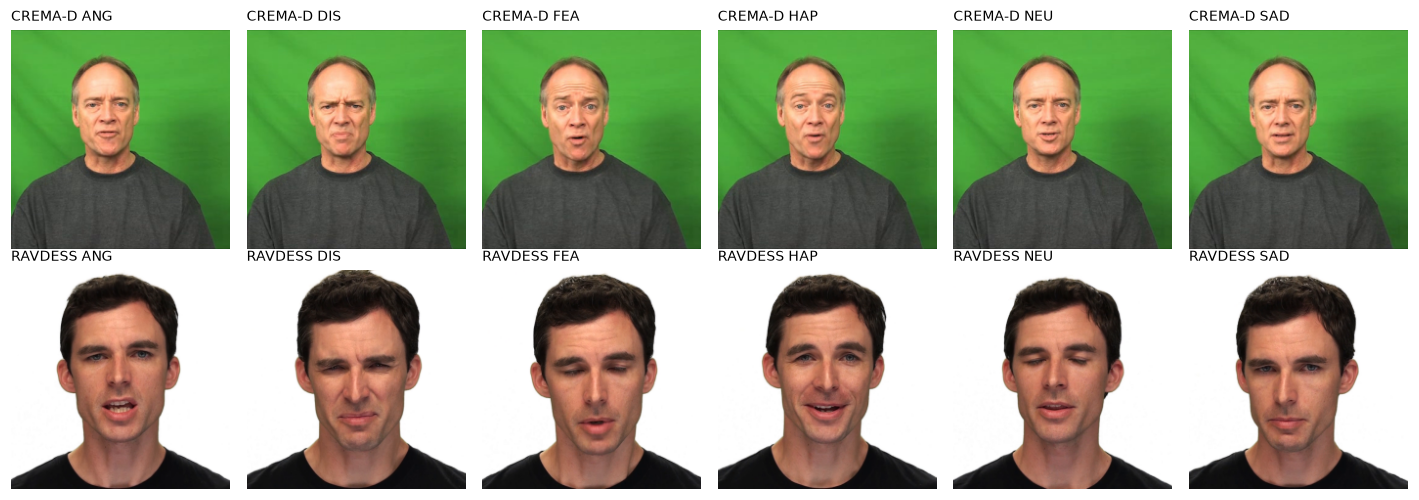

In [24]:
EMO6 = ["ANG", "DIS", "FEA", "HAP", "NEU", "SAD"]
fig, axes = plt.subplots(2, 6, figsize=(13, 4.6))
with h5py.File(paths.processed / "cremad.h5") as h5:
    for ax, e in zip(axes[0], EMO6):
        r = clips_cd.index[(clips_cd.actor_id == 1001) & (clips_cd.sentence == "ITS") & (clips_cd.displayed_emotion == e)][0]
        ax.imshow(h5["video"][r, 5]); ax.set_title(f"CREMA-D {e}", fontsize=9); ax.axis("off")
for ax, e in zip(axes[1], EMO6):
    hit = vid[(vid.actor == 1) & (vid.emotion6 == e) & (vid.statement == 1) & (vid.repetition == 1) & (vid.intensity == "normal")]
    if len(hit):
        ax.imshow(mids[hit.video.iloc[0]])
    ax.set_title(f"RAVDESS {e}", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

### 8c. Where the face is, and how big

Face width as a share of the 224-pixel frame, and the face centre position, per clip (median over the ten
frames). The visual encoder has no face detector: it sees whatever the centre crop contains, so a face that is
much smaller or placed elsewhere in one corpus is a different input distribution.

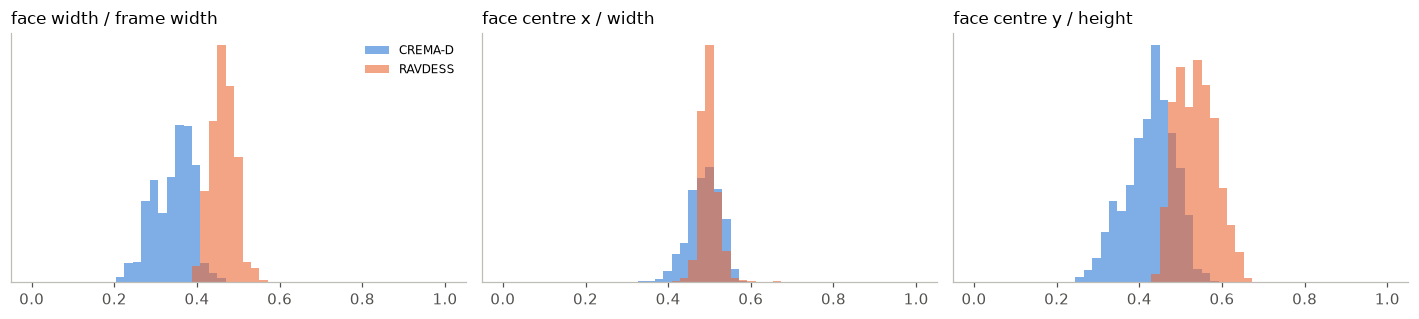

,CREMA-D,RAVDESS
face found (share of frames),1.00,1.00
face width (median),0.35,0.46
face area share of frame,0.12,0.21
centre x,0.49,0.50
centre y,0.44,0.54


In [25]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.0))
for ax, col, label in zip(axes, ["face_size", "face_cx", "face_cy"], ["face width / frame width", "face centre x / width", "face centre y / height"]):
    a, b = vid_cd[col].dropna(), vid[col].dropna()
    bins = np.linspace(0, 1, 50)
    ax.hist(a, bins, density=True, color=BLUE, alpha=0.6, label="CREMA-D"); ax.hist(b, bins, density=True, color=ORANGE, alpha=0.6, label="RAVDESS")
    ax.set_title(label); ax.set_yticks([])
axes[0].legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()
pd.DataFrame({name: {"face found (share of frames)": d.face_found.mean(), "face width (median)": d.face_size.median(),
                     "face area share of frame": (d.face_size ** 2).median(), "centre x": d.face_cx.median(), "centre y": d.face_cy.median()}
              for name, d in [("CREMA-D", vid_cd), ("RAVDESS", vid)]}).round(2)

### 8d. Background and colour: a visual corpus fingerprint?

The border of every frame (outer 12 pixels) is background. Its colour and texture, plus overall brightness, are
fed to the same corpus classifier as in §5d (actor-grouped folds, balanced classes, 50% = indistinguishable).

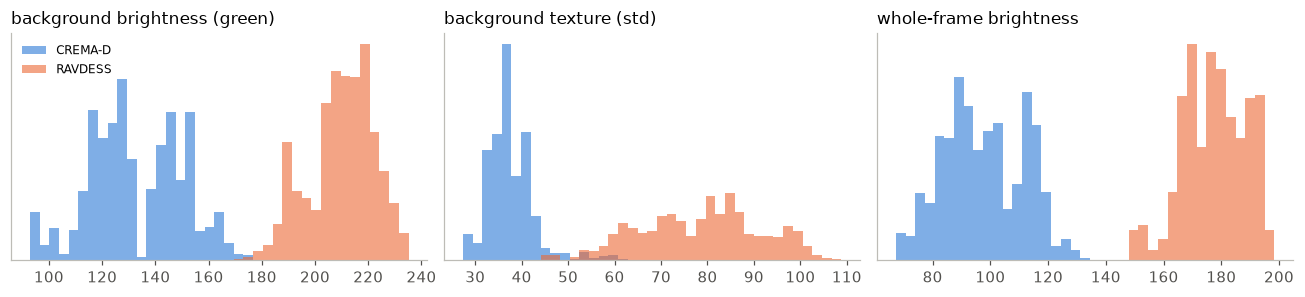

which corpus? from 5 background/brightness numbers: 100.0% ± 0.0% (6 actor-grouped folds)


In [26]:
COLOR = ["border_r", "border_g", "border_b", "border_std", "brightness"]
fig, axes = plt.subplots(1, 3, figsize=(12, 2.8))
for ax, col, label in zip(axes, ["border_g", "border_std", "brightness"], ["background brightness (green)", "background texture (std)", "whole-frame brightness"]):
    a, b = vid_cd[col], vid[col]
    bins = np.linspace(min(a.min(), b.min()), max(a.max(), b.max()), 40)
    ax.hist(a, bins, density=True, color=BLUE, alpha=0.6, label="CREMA-D"); ax.hist(b, bins, density=True, color=ORANGE, alpha=0.6, label="RAVDESS")
    ax.set_title(label); ax.set_yticks([])
axes[0].legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

n = min(len(vid), len(vid_cd))
Xv = pd.concat([vid_cd[COLOR].iloc[:n], vid[COLOR].iloc[:n]]).fillna(0)
yv = np.r_[np.zeros(n), np.ones(n)]
gv = np.r_[vid_cd.actor_id.values[:n], 10_000 + vid.actor.values[:n]]
folds = min(6, len(np.unique(vid.actor.values[:n])))
s = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)), Xv, yv, groups=gv,
                    cv=GroupKFold(folds), scoring="balanced_accuracy")
print(f"which corpus? from 5 background/brightness numbers: {s.mean():.1%} ± {s.std():.1%} ({folds} actor-grouped folds)")

### 8e. Do the ten frames show the person speaking?

The ten frames are spread over the **whole file**. RAVDESS files are about half silence (§6), so some frames
fall before the actor starts or after they finish: a resting face. The audio timing of the matching audio-only
file (same take) gives the speech interval; CREMA-D files are cut around the speech, so all ten frames are.

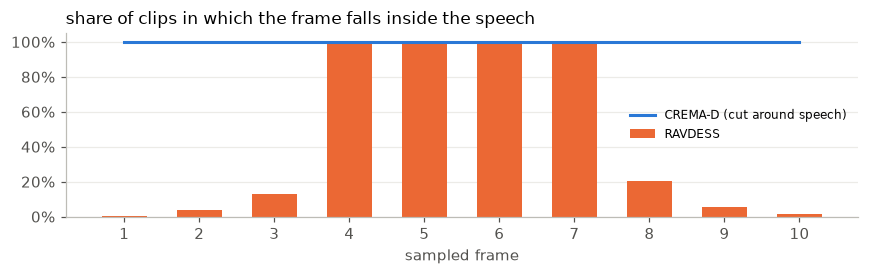

RAVDESS: 4.4 of 10 frames fall inside the speech on average (min 3, max 9)


In [27]:
timing = rav6.set_index("video")[[]].join(desc6.set_index(rav6.video)[["duration_s", "lead_s", "trail_s"]])
pos = np.linspace(0, 1, 10)
in_speech = np.array([((pos * d >= l) & (pos * d <= d - t)) for d, l, t in timing[["duration_s", "lead_s", "trail_s"]].to_numpy()])
share = in_speech.mean(axis=0)
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.bar(np.arange(1, 11), share, color=ORANGE, width=0.6, label="RAVDESS")
ax.plot(np.arange(1, 11), np.ones(10), color=BLUE, lw=2, label="CREMA-D (cut around speech)")
ax.set_xticks(range(1, 11)); ax.set_xlabel("sampled frame"); ax.yaxis.set_major_formatter("{x:.0%}")
ax.set_title("share of clips in which the frame falls inside the speech"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
print(f"RAVDESS: {in_speech.sum(1).mean():.1f} of 10 frames fall inside the speech on average "
      f"(min {in_speech.sum(1).min()}, max {in_speech.sum(1).max()})")

### 8f. Facial movement by emotion and intensity

Mean absolute pixel change between consecutive sampled frames inside the face box. More movement = more
expressive or more talking. For RAVDESS the change is shown per step, so the silent edges (steps 1 and 9) can be
compared with the middle.

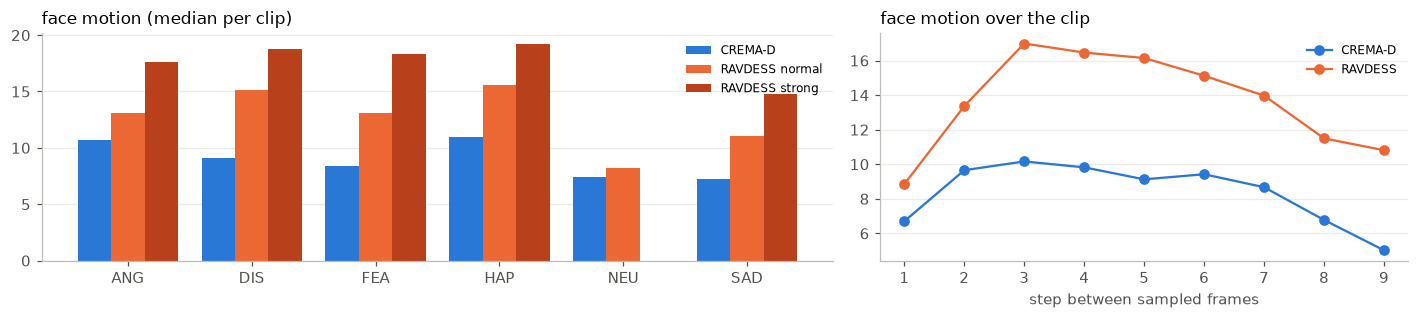

,CREMA-D,RAVDESS normal,RAVDESS strong
ANG,10.68,13.06,17.64
DIS,9.08,15.10,18.74
FEA,8.36,13.09,18.28
HAP,10.99,15.53,19.21
NEU,7.42,8.18,NaN
SAD,7.20,11.02,14.75


In [28]:
motion = pd.DataFrame({
    "CREMA-D": vid_cd.groupby("displayed_emotion").face_motion.median(),
    "RAVDESS normal": vid[vid.intensity == "normal"].groupby("emotion6").face_motion.median(),
    "RAVDESS strong": vid[vid.intensity == "strong"].groupby("emotion6").face_motion.median(),
}).loc[EMO6]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.0), gridspec_kw={"width_ratios": [3, 2]})
x = np.arange(len(EMO6)); w = 0.27
for i, (col, color) in enumerate(zip(motion.columns, [BLUE, ORANGE, "#b8401a"])):
    axes[0].bar(x + (i - 1) * w, motion[col], w, color=color, label=col)
axes[0].set_xticks(x, EMO6); axes[0].set_title("face motion (median per clip)"); axes[0].legend(frameon=False, fontsize=8)
steps = np.array([list(map(float, s.split(","))) for s in vid.face_motion_per_step.dropna()])
steps_cd = np.array([list(map(float, s.split(","))) for s in vid_cd.face_motion_per_step.dropna()])
axes[1].plot(range(1, 10), np.median(steps_cd, 0), color=BLUE, marker="o", label="CREMA-D")
axes[1].plot(range(1, 10), np.median(steps, 0), color=ORANGE, marker="o", label="RAVDESS")
axes[1].set_xticks(range(1, 10)); axes[1].set_xlabel("step between sampled frames"); axes[1].set_title("face motion over the clip")
axes[1].legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()
motion.round(2)

**Takeaways (video)** (all 24 RAVDESS actors)
- **The background names the corpus.** CREMA-D was filmed against a **green screen**, RAVDESS against **white**.
  Five numbers about the frame border identify the corpus **100%** of the time. A visual encoder that sees the
  whole centre crop gets a perfect client label for free, the visual twin of RAVDESS's leading silence (§6).
- **Different framing.** CREMA-D is head-and-shoulders with the face in the upper half (face ≈ 35% of the frame
  width, 12% of its area); RAVDESS is a close-up with the face centred (≈ 46% of the width, 21% of the area). After
  the 224×224 resize a RAVDESS face has ~1.7× the pixels of a CREMA-D face.
- **Most RAVDESS frames show a silent face.** Only **4.4 of the 10** sampled frames fall inside the speech
  (frames 4–7 almost always, the outer ones almost never): the encoder sees a resting face more than half the
  time, while every CREMA-D frame shows the actor speaking. The motion curve agrees: RAVDESS faces move most in
  the middle of the clip.
- **RAVDESS faces move more, and intensity is visible.** Median face motion is higher than CREMA-D's for every
  emotion, and *strong* clearly above *normal* for every emotion (anger 17.6 vs 13.1), the visual counterpart of §5c. Neutral and sad
  move least in both corpora.

### 8g. What this means for the kiosk setting and for training

A CAPE kiosk camera will see a customer at arm's length, roughly frontal, in front of **whatever is behind them in
that store**. Each kiosk is a federated client with its own background, lighting and camera, i.e. exactly the
visual feature skew measured above, only stronger. Three treatments follow, all preprocessing (same for every
corpus, so the comparison with the current CREMA-D runs stays clean):

| Issue | If ignored | Treatment |
|---|---|---|
| background identifies the corpus / kiosk (8d) | the model learns the background as a shortcut; it will not transfer to a new store | **crop to the face** with a detector (YuNet), a fixed margin around the box, then resize to 224 |
| face size differs 1.7× (8c) | the encoder must learn two scales of the same face | the same face crop normalises scale and position |
| 56% of RAVDESS frames are silent faces (8e) | the visual stream is diluted with resting faces | sample the 10 frames **inside the speech interval** (from the audio trim of §6), not over the whole file |

Face cropping was out of scope for the CREMA-D-only protocol (one background, one framing, so it could not
matter). With a second corpus, and with CAPE's kiosks in view, it becomes the visual counterpart of trimming
silence and per-client normalisation: the three together remove the recording fingerprints and leave what a
federated model should learn, the emotion.

## 9. Zero-shot: do our trained CREMA-D models work on RAVDESS?

The trained networks themselves (not linear probes) are run on RAVDESS's 6-emotion clips, without retraining.
RAVDESS is only a test set here; CREMA-D's test actors are not touched (the CREMA-D column is each run's own,
already-scored test result). Produced by `scripts/ravdess_probe.py zero-shot`; each step adds one change on the
RAVDESS side only:

| Step | Change |
|---|---|
| A | as is: whole-file MFCC with the run's CREMA-D audio statistics, frames over the whole file, centre crop |
| B | + silence trimmed (§6) |
| C | + RAVDESS's own audio statistics (per-client normalisation, §7c) |
| D | + frames sampled inside the speech (§8e) |
| E | + CREMA-D-like framing: face zoomed out to CREMA-D's size and position (§8c) |

Models: U1 (audio only) and C1 (audio + simple visual), protocol 3, splits 0–2; **D2** (audio + deep visual,
gated: our best CREMA-D model) is the protocol-2 split-0 run as a preview until its protocol-3 run exists.
Chance-level valence macro-F1 (always "negative") is 0.27.

In [29]:
PROBE = RAV / "probe"
zs = pd.read_csv(PROBE / "zero_shot.csv")
zs["model"] = zs.config.str.split("_").str[0].str.upper()
n_probe = len(pd.read_csv(PROBE / "clips.csv"))
print(f"RAVDESS clips in the probe: {n_probe} of {len(rav6)}")
summary = zs.groupby(["model", "variant"]).agg(
    runs=("run", "nunique"), valence_f1=("valence_macro_f1", "mean"), emotion_f1=("emotion_macro_f1", "mean"),
    intensity_mae=("intensity_mae", "mean"), says_negative=("predicted_negative_share", "mean"),
    cremad_test_valence_f1=("cremad_test_valence_macro_f1", "mean"))
summary.style.format({c: "{:.3f}" for c in ["valence_f1", "emotion_f1", "intensity_mae", "cremad_test_valence_f1"]}
                     | {"says_negative": "{:.0%}"})

RAVDESS clips in the probe: 1056 of 1056


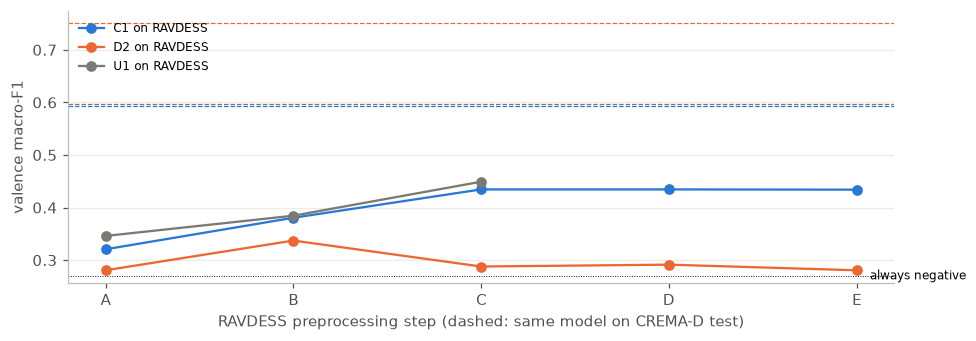

In [30]:
fig, ax = plt.subplots(figsize=(9, 3.2))
colors = {"U1": "#7a7974", "C1": BLUE, "D2": ORANGE}
for model, g in zs.groupby("model"):
    m = g.groupby("variant").valence_macro_f1.mean()
    ax.plot(m.index, m.values, marker="o", color=colors.get(model, MUTED), label=f"{model} on RAVDESS")
    ax.axhline(g.cremad_test_valence_macro_f1.mean(), color=colors.get(model, MUTED), lw=0.8, ls="--")
ax.axhline(0.27, color="black", lw=0.6, ls=":"); ax.text(4.05, 0.27, " always negative", va="center", fontsize=8)
ax.set_ylabel("valence macro-F1"); ax.set_xlabel("RAVDESS preprocessing step (dashed: same model on CREMA-D test)")
ax.legend(frameon=False, fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()

## 10. Where does the visual encoder look? (Grad-CAM)

Grad-CAM (Selvaraju et al., ICCV 2017) highlights the image regions that drive the predicted valence class, at
the last spatial layer of the visual encoder. Computed on 96 CREMA-D clips from split 0's **validation** actors
and 96 RAVDESS clips, for the three RAVDESS frame variants. *Saliency on face* is the share of the map inside the
YuNet face box; the *focus ratio* divides it by the face's share of the image (1 = no preference for the face,
above 1 = the network looks at the face).

In [31]:
sal = pd.concat([pd.read_csv(f) for f in sorted(PROBE.glob("saliency_*.csv"))])
sal["model"] = sal.run.str.split("_|-").str[0].str.upper()
sal[["model", "corpus", "frames", "saliency_on_face", "face_area", "face_focus_ratio"]].style.format(
    {"saliency_on_face": "{:.0%}", "face_area": "{:.0%}", "face_focus_ratio": "{:.2f}"}).hide(axis="index")

model,corpus,frames,saliency_on_face,face_area,face_focus_ratio
C1,CREMA-D,as trained,0%,16%,0.00
C1,RAVDESS,whole,11%,28%,0.41
C1,RAVDESS,speech,11%,28%,0.40
C1,RAVDESS,framed,7%,16%,0.41
D2,CREMA-D,as trained,42%,16%,2.66
D2,RAVDESS,whole,30%,28%,1.05
D2,RAVDESS,speech,30%,28%,1.04
D2,RAVDESS,framed,19%,16%,1.16


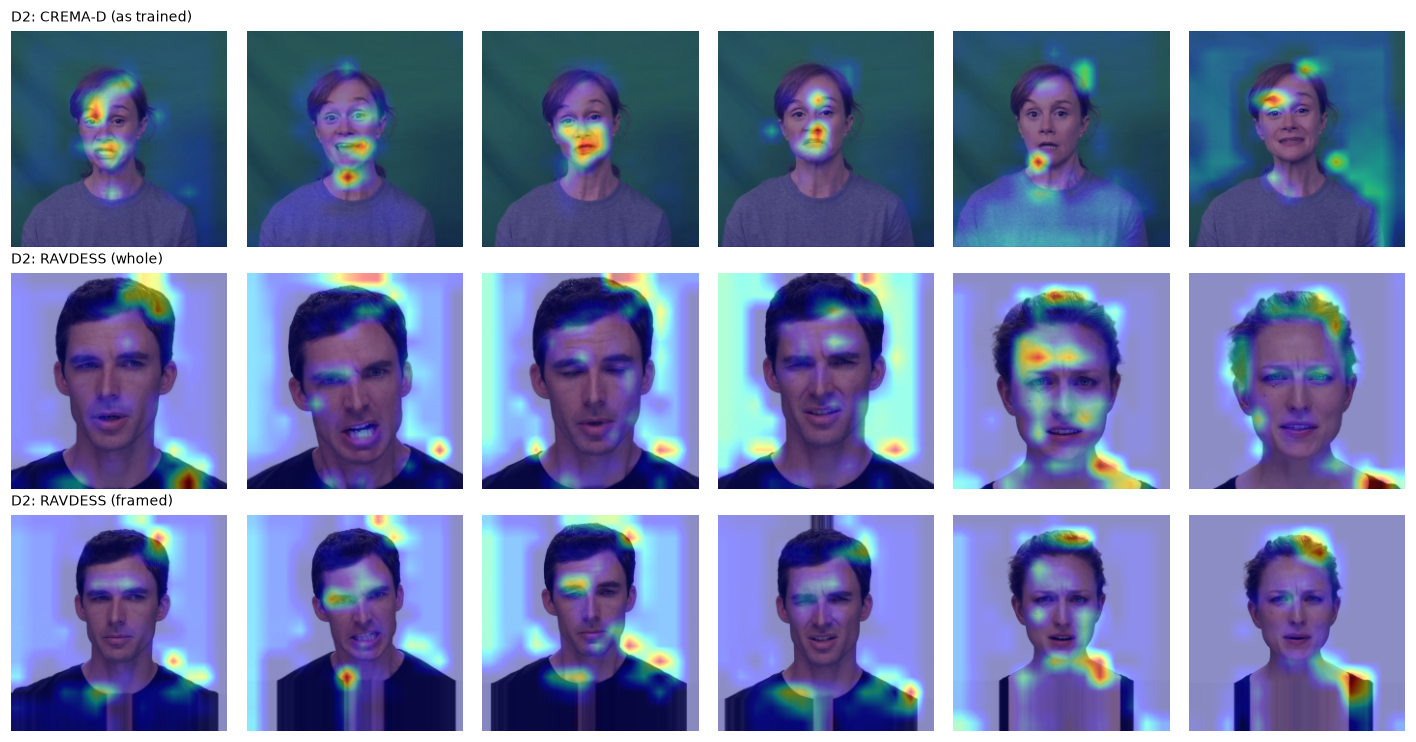

In [32]:
ex = np.load(next(PROBE.glob("saliency_d2-*.npz")))
rows_cam = [("CREMA-D", "as trained"), ("RAVDESS", "whole"), ("RAVDESS", "framed")]
fig, axes = plt.subplots(3, 6, figsize=(13, 6.8))
for r, (corpus, kind) in enumerate(rows_cam):
    frames_, cams = ex[f"{corpus}|{kind}|frames"], ex[f"{corpus}|{kind}|cam"]
    for c in range(6):
        axes[r, c].imshow(frames_[c]); axes[r, c].imshow(cams[c] / (cams[c].max() + 1e-9), cmap="jet", alpha=0.45)
        axes[r, c].axis("off")
    axes[r, 0].set_title(f"D2: {corpus} ({kind})", fontsize=9)
plt.tight_layout(); plt.show()

**Takeaways (zero-shot and saliency)** (all 24 RAVDESS actors; D2 is the protocol-2 split-0 run)
- **Audio transfers partly, and the §7c treatments recover a third of the gap.** U1 and C1 fall from ~0.60 on
  CREMA-D to ~0.33 on RAVDESS as is, close to always-negative. Trimming silence and normalising with RAVDESS's own
  statistics bring them to **0.44 (C1) and 0.45 (U1)**. Per-client normalisation is the bigger step for emotion F1 (0.24 → 0.37).
  C1 behaves exactly like U1: its simple visual encoder contributes nothing (as on CREMA-D).
- **The best CREMA-D model fails completely.** D2 (0.75 on CREMA-D) answers "negative" for **98–100%** of
  RAVDESS clips in every variant, including CREMA-D-like framing. Better in-domain, worse out of domain: the
  deep visual stream that makes D2 strong on CREMA-D is what breaks on RAVDESS.
- **Grad-CAM shows why.** On CREMA-D, D2 looks at the face: 42% of its saliency falls on a face that covers 16%
  of the image (focus ratio **2.6**), mostly mouth and eyes. On RAVDESS the focus ratio drops to **1.0–1.2**: the
  map spreads over hair edges, the shirt and the background, with or without CREMA-D-like framing. The face is
  where it should be and the right size, but the encoder no longer finds it: the surrounding colours (white
  background, black clothing instead of green screen and grey T-shirts) change the activations it learned on.
- **This is the background effect, measured.** It confirms the concern: a visual encoder trained on one
  background does not transfer to another, even when face size and position match. A face crop (§8g) removes most
  of the context; training on two corpora (or many kiosks) with crops is what should teach the encoder to rely on
  the face alone. (A protocol-3 D2 was never trained: the V1 queue was stopped before it; V2 will retrain.)